## 1. Import libraries
pandas and numpy handle the data and maths. matplotlib and seaborn draw charts. scikit-learn, XGBoost and LightGBM provide the models and the scores.

In [28]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


## 2. Load the data
The dataset has 4,446,966 player records and 29 columns. Each row is one player in one match, and `winPlacePerc` is the target we want to predict.

In [29]:
DATA_PATH = "pubg.csv"

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(657469, 29)


,Id,groupId,matchId,assists,boosts,damageDealt,DBNOs,headshotKills,heals,killPlace,...,revives,rideDistance,roadKills,swimDistance,teamKills,vehicleDestroys,walkDistance,weaponsAcquired,winPoints,winPlacePerc
0,7f96b2f878858a,4d4b580de459be,a10357fd1a4a91,0,0,0.00,0,0,0,60,...,0.0,0.0000,0.0,0.00,0.0,0.0,244.80,1.0,1466.0,0.4444
1,eef90569b9d03c,684d5656442f9e,aeb375fc57110c,0,0,91.47,0,0,0,57,...,0.0,0.0045,0.0,11.04,0.0,0.0,1434.00,5.0,0.0,0.6400
2,1eaf90ac73de72,6a4a42c3245a74,110163d8bb94ae,1,0,68.00,0,0,0,47,...,0.0,0.0000,0.0,0.00,0.0,0.0,161.80,2.0,0.0,0.7755
3,4616d365dd2853,a930a9c79cd721,f1f1f4ef412d7e,0,0,32.90,0,0,0,75,...,0.0,0.0000,0.0,0.00,0.0,0.0,202.70,3.0,0.0,0.1667
4,315c96c26c9aac,de04010b3458dd,6dc8ff871e21e6,0,0,100.00,0,0,0,45,...,0.0,0.0000,0.0,0.00,0.0,0.0,49.75,2.0,0.0,0.1875


## 3. Sample the data
The full file is too large to work with comfortably, so about 500,000 rows are used. Whole matches are sampled instead of random rows, so teams and match-level features stay valid. Result: 498,582 rows from 5,393 matches.

In [30]:
SAMPLE_ROWS = 500_000
RANDOM_STATE = 42

if len(df) > SAMPLE_ROWS:
    matches = df['matchId'].drop_duplicates().sample(frac=SAMPLE_ROWS/len(df), random_state=RANDOM_STATE)
    df = df[df['matchId'].isin(matches)].reset_index(drop=True)

print(df.shape)

(499478, 29)


## 4. Data structure and quality checks
`df.info()` shows column types, `isnull()` counts missing values, and `describe()` gives summary statistics.
**Findings:** no missing values and no duplicate rows. Several columns (kills, weaponsAcquired, walkDistance) have a much larger maximum than their 75th percentile, which points to outliers.

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499478 entries, 0 to 499477
Data columns (total 29 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Id               499478 non-null  object 
 1   groupId          499478 non-null  object 
 2   matchId          499478 non-null  object 
 3   assists          499478 non-null  int64  
 4   boosts           499478 non-null  int64  
 5   damageDealt      499478 non-null  float64
 6   DBNOs            499478 non-null  int64  
 7   headshotKills    499478 non-null  int64  
 8   heals            499478 non-null  int64  
 9   killPlace        499478 non-null  int64  
 10  killPoints       499478 non-null  int64  
 11  kills            499478 non-null  int64  
 12  killStreaks      499478 non-null  int64  
 13  longestKill      499478 non-null  float64
 14  matchDuration    499478 non-null  int64  
 15  matchType        499478 non-null  object 
 16  maxPlace         499478 non-null  int6

In [32]:
print('Missing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('Duplicate rows:', df.duplicated().sum())
print('Unique matches:', df['matchId'].nunique())
print('Unique groups:', df['groupId'].nunique())

Missing values:
revives            1
rideDistance       1
roadKills          1
swimDistance       1
teamKills          1
vehicleDestroys    1
walkDistance       1
weaponsAcquired    1
winPoints          1
winPlacePerc       1
dtype: int64
Duplicate rows: 0
Unique matches: 36421
Unique groups: 428986


## 5. Target distribution
A histogram and boxplot show how `winPlacePerc` is spread.
**Finding:** the values are spread fairly evenly between 0 and 1, with spikes at 0 (last place) and 1 (winner). The mean is about 0.47.

In [33]:
print('Missing target before:', df['winPlacePerc'].isnull().sum())
df = df.dropna(subset=['winPlacePerc']).reset_index(drop=True)
print('Missing target after:', df['winPlacePerc'].isnull().sum())

Missing target before: 1
Missing target after: 0


In [34]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
assists,499477.0,0.233082,0.588356,0.0,0.0,0.0000,0.0000,21.0
boosts,499477.0,1.107104,1.714734,0.0,0.0,0.0000,2.0000,33.0
damageDealt,499477.0,130.818259,170.972367,0.0,0.0,84.6300,185.9000,6616.0
DBNOs,499477.0,0.658925,1.146641,0.0,0.0,0.0000,1.0000,33.0
headshotKills,499477.0,0.226689,0.598479,0.0,0.0,0.0000,0.0000,40.0
heals,499477.0,1.368187,2.671652,0.0,0.0,0.0000,2.0000,52.0
killPlace,499477.0,47.576439,27.459158,1.0,24.0,47.0000,71.0000,100.0
killPoints,499477.0,509.497264,628.513546,0.0,0.0,0.0000,1175.0000,2152.0
kills,499477.0,0.925270,1.554452,0.0,0.0,0.0000,1.0000,65.0
killStreaks,499477.0,0.545366,0.711546,0.0,0.0,0.0000,1.0000,14.0


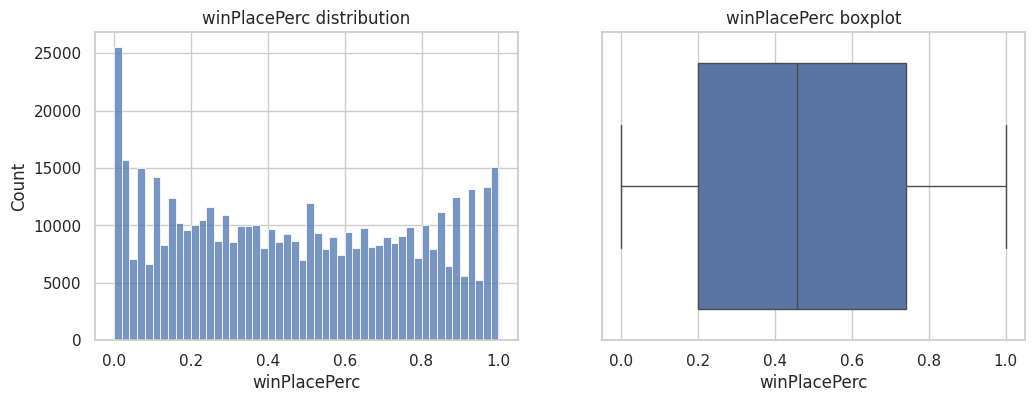

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['winPlacePerc'], bins=50, ax=ax[0])
ax[0].set_title('winPlacePerc distribution')
sns.boxplot(x=df['winPlacePerc'], ax=ax[1])
ax[1].set_title('winPlacePerc boxplot')
plt.show()

## 6. Match types
Counts how many records each game mode has.
**Finding:** squad-fpp, duo-fpp, squad and solo-fpp dominate. Types such as normal-*, crashfpp and flare* have very few rows, so they are grouped later.

matchType
squad-fpp           197870
duo-fpp             111265
squad                70460
solo-fpp             60092
duo                  35237
solo                 20734
normal-squad-fpp      1822
crashfpp               678
normal-duo-fpp         597
flaretpp               276
normal-solo-fpp        174
flarefpp                96
normal-squad            72
crashtpp                40
normal-solo             38
normal-duo              26
Name: count, dtype: int64


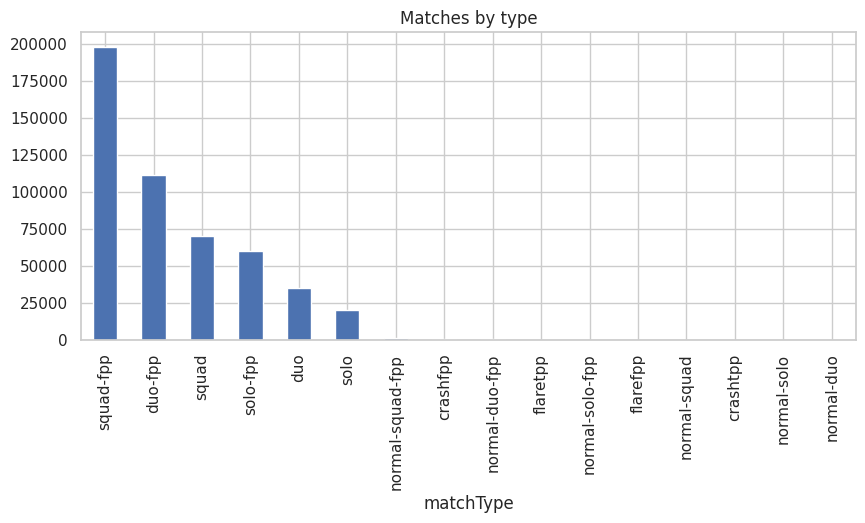

In [36]:
print(df['matchType'].value_counts())
df['matchType'].value_counts().plot(kind='bar', figsize=(10, 4), title='Matches by type')
plt.show()

## 7. Correlation with the target
Correlation measures how strongly two columns move together (-1 to +1).
**Findings:** walkDistance (+0.81), killPlace (-0.72), boosts (+0.63) and weaponsAcquired (+0.57) are the strongest. killPlace is negative because a smaller place number means a better rank. Surviving and moving matter more than raw kills.

In [37]:
num_cols = df.select_dtypes(include=np.number).columns.drop('winPlacePerc')
corr = df[list(num_cols) + ['winPlacePerc']].corr()

top = corr['winPlacePerc'].drop('winPlacePerc').sort_values(key=abs, ascending=False)
print(top.head(15))

walkDistance       0.811240
killPlace         -0.718951
boosts             0.635152
weaponsAcquired    0.584533
damageDealt        0.440800
heals              0.429075
kills              0.420812
longestKill        0.409742
killStreaks        0.377195
rideDistance       0.342904
assists            0.297100
DBNOs              0.279917
headshotKills      0.279153
revives            0.241231
swimDistance       0.152182
Name: winPlacePerc, dtype: float64


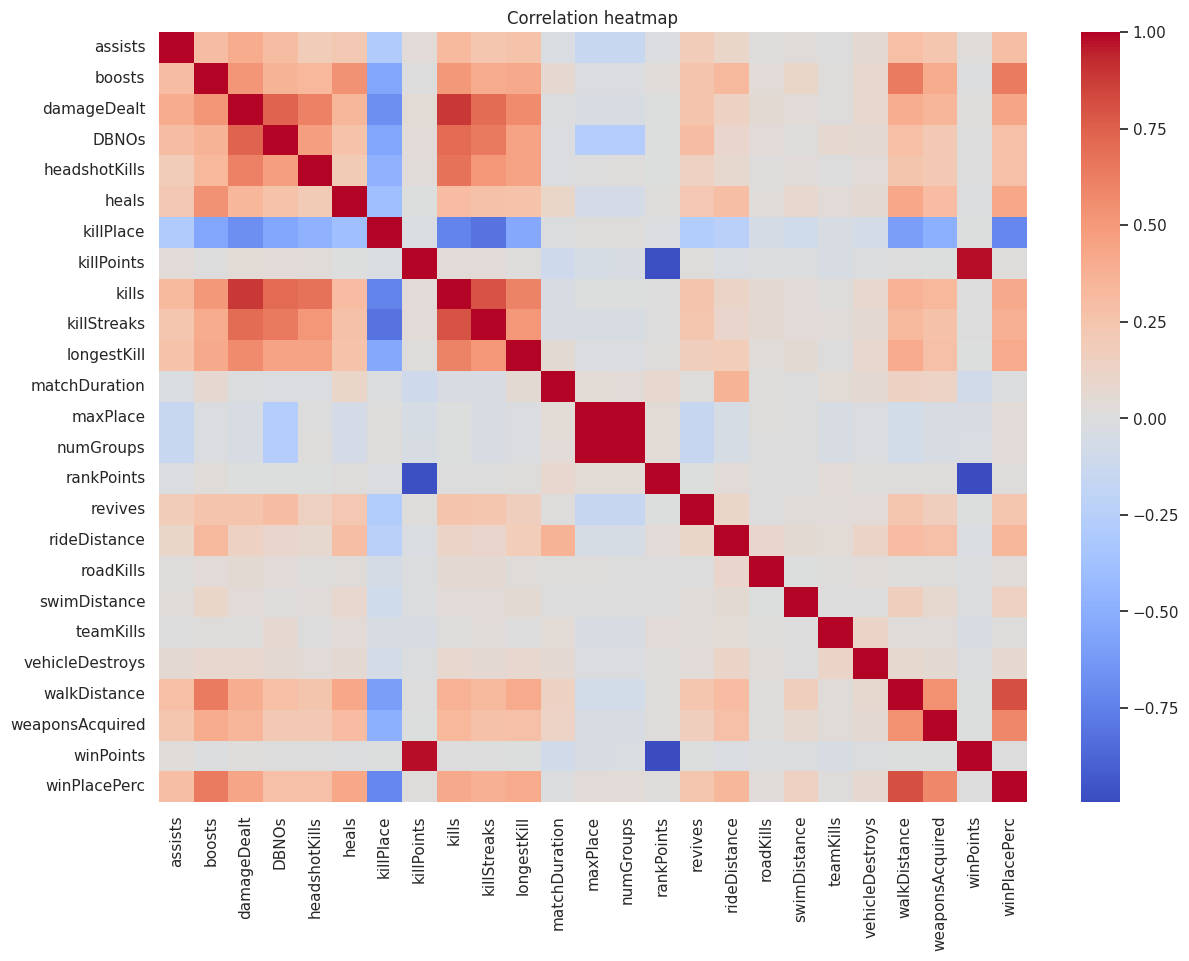

In [38]:
plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.show()

## 8. Relationships with the top features
Scatter plots of the strongest features against `winPlacePerc`.
**Finding:** boosts, heals and damageDealt rise and then flatten, so the relationships are not straight lines. This is a reason to use tree-based models.

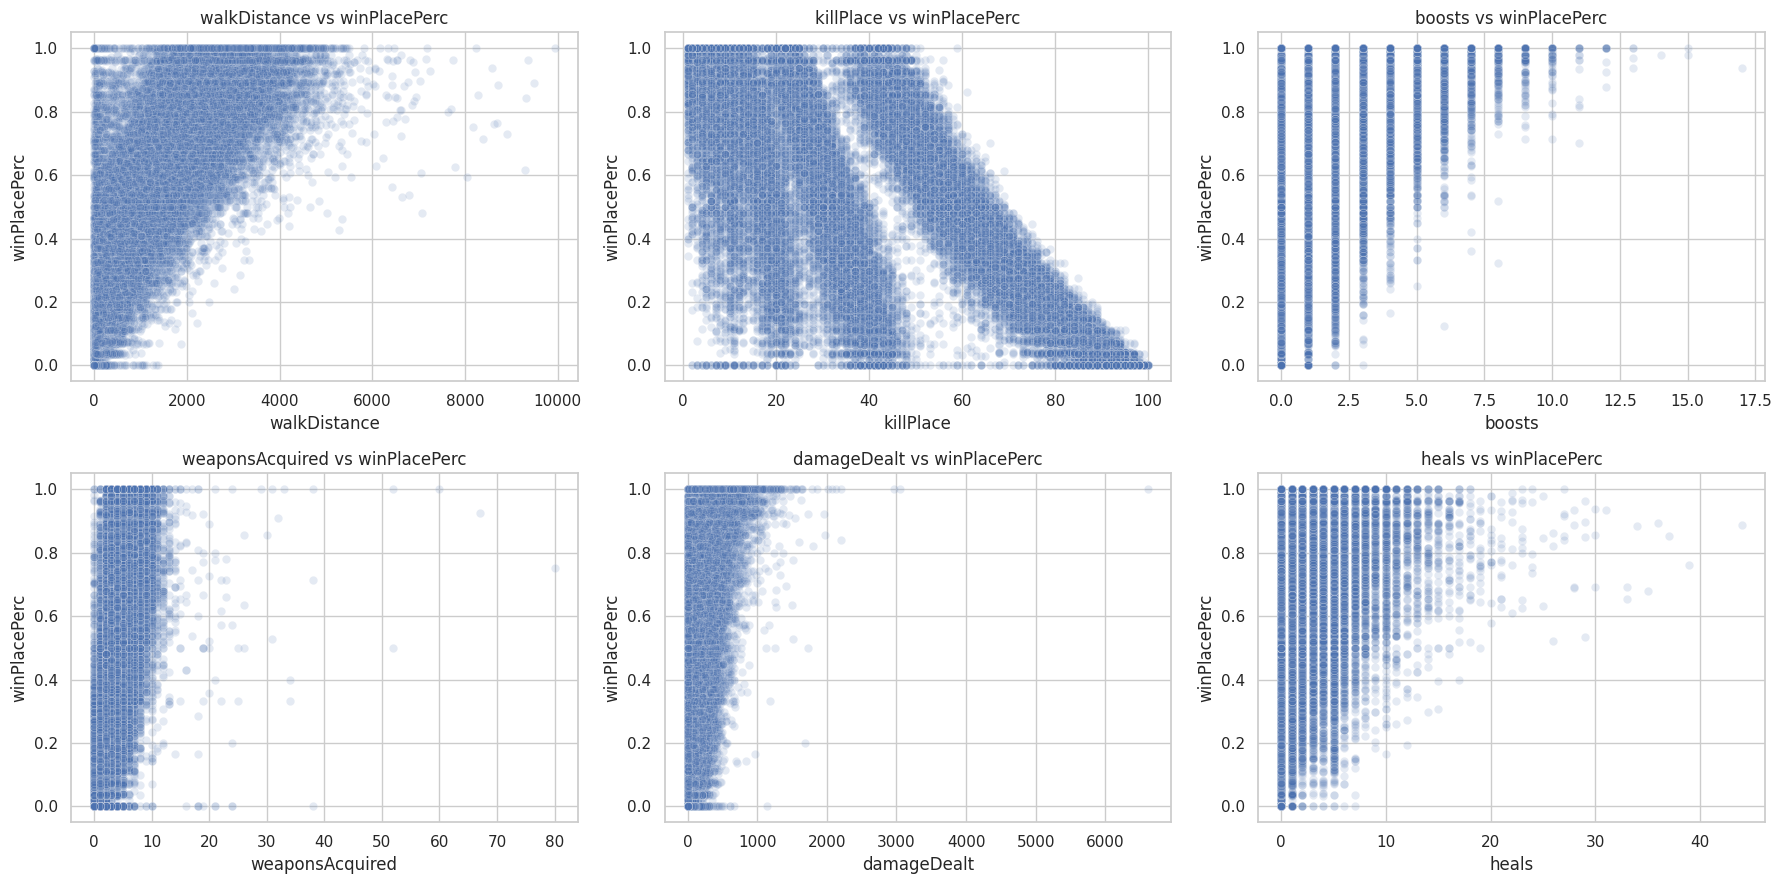

In [39]:
sample = df.sample(50_000, random_state=RANDOM_STATE)
cols = ['walkDistance', 'killPlace', 'boosts', 'weaponsAcquired', 'damageDealt', 'heals']

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, c in zip(ax.ravel(), cols):
    sns.scatterplot(data=sample, x=c, y='winPlacePerc', alpha=0.15, ax=a)
    a.set_title(f'{c} vs winPlacePerc')
plt.tight_layout()
plt.show()

## 9. Detect suspicious players
Counts rows with impossible or extreme values, such as kills with zero movement, more than 20 kills, or more than 80 weapons.
**Finding:** very few rows (for example 185 players with kills but no movement). These look like cheaters or bugs.

In [40]:
total_dist = df['walkDistance'] + df['rideDistance'] + df['swimDistance']

anomalies = {
    'kills > 20':                 (df['kills'] > 20).sum(),
    'headshots > kills':          (df['headshotKills'] > df['kills']).sum(),
    'kills with zero movement':   ((df['kills'] > 0) & (total_dist == 0)).sum(),
    'roadKills > 5':              (df['roadKills'] > 5).sum(),
    'longestKill > 1000 m':       (df['longestKill'] > 1000).sum(),
    'weaponsAcquired > 80':       (df['weaponsAcquired'] > 80).sum(),
    'heals > 40':                 (df['heals'] > 40).sum(),
    'walkDistance > 10000 m':     (df['walkDistance'] > 10000).sum(),
}
pd.Series(anomalies, name='rows')

,rows
kills > 20,50
headshots > kills,0
kills with zero movement,171
roadKills > 5,12
longestKill > 1000 m,3
weaponsAcquired > 80,0
heals > 40,12
walkDistance > 10000 m,27


## 10. Clean the data
Rows with clearly impossible values are removed. **206 rows (0.041%)** were dropped, leaving 498,376 rows. Removing them protects the model from misleading examples at almost no cost.

In [41]:
def clean(d):
    d = d.copy()
    total_dist = d['walkDistance'] + d['rideDistance'] + d['swimDistance']
    bad = (
        (d['kills'] > 30) |
        (d['headshotKills'] > d['kills']) |
        ((d['kills'] > 0) & (total_dist == 0)) |
        (d['roadKills'] > 10) |
        (d['longestKill'] > 1000) |
        (d['weaponsAcquired'] > 80) |
        (d['heals'] > 80)
    )
    return d[~bad].reset_index(drop=True)

n_before = len(df)
df = clean(df)
removed = n_before - len(df)
print(f'Removed {removed:,} rows ({removed / n_before:.3%})')
print('New shape:', df.shape)

Removed 181 rows (0.036%)
New shape: (499296, 29)


## 11. Feature engineering (new clues)
- **Play-style features:** total distance, heals plus boosts, headshot rate, kills and heals per distance.
- **Match features:** players joined, and kills and damage adjusted for match size.
- **Rank-in-match features:** each player's percentile within their own match.
**Why:** a stat means different things in different matches, so comparing players inside the same match is fairer.

In [42]:
def engineer(d):
    d = d.copy()

    d['totalDistance']   = d['walkDistance'] + d['rideDistance'] + d['swimDistance']
    d['healsAndBoosts']  = d['heals'] + d['boosts']
    d['headshotRate']    = (d['headshotKills'] / d['kills']).fillna(0)
    d['killsPerWalkDist'] = d['kills'] / (d['walkDistance'] + 1)
    d['healsPerWalkDist'] = d['healsAndBoosts'] / (d['walkDistance'] + 1)

    d['playersJoined'] = d.groupby('matchId')['matchId'].transform('count')
    d['killsNorm']  = d['kills'] * ((100 - d['playersJoined']) / 100 + 1)
    d['damageNorm'] = d['damageDealt'] * ((100 - d['playersJoined']) / 100 + 1)

    for c in ['kills', 'damageDealt', 'walkDistance', 'healsAndBoosts', 'weaponsAcquired']:
        d[f'{c}_matchRank'] = d.groupby('matchId')[c].rank(pct=True)

    return d

## 11b. Team features and match mode
Teammates share the same `winPlacePerc`, so team averages (kills, walking, damage, kill place) and team size are added. The 15 match types are grouped into solo, duo, squad and other, plus a first-person flag, and one-hot encoded so models can use them.

In [43]:
def engineer_team(d):
    d = d.copy()

    g = d.groupby(['matchId', 'groupId'])
    d['teamSize']          = g['Id'].transform('count')
    d['teamMeanKills']     = g['kills'].transform('mean')
    d['teamMeanWalk']      = g['walkDistance'].transform('mean')
    d['teamMeanDamage']    = g['damageDealt'].transform('mean')
    d['teamMeanKillPlace'] = g['killPlace'].transform('mean')

    def mode(s):
        if 'solo' in s:  return 'solo'
        if 'duo' in s:   return 'duo'
        if 'squad' in s: return 'squad'
        return 'other'

    d['matchMode'] = d['matchType'].map(mode)
    d['isFPP'] = d['matchType'].str.contains('fpp').astype(int)
    d = pd.concat([d, pd.get_dummies(d['matchMode'], prefix='mode').astype(int)], axis=1)
    return d

df = engineer(df)
df = engineer_team(df)
print(df.shape)
df[['totalDistance', 'healsAndBoosts', 'playersJoined', 'walkDistance_matchRank',
    'teamSize', 'teamMeanKills', 'matchMode']].head()

(499296, 53)


,totalDistance,healsAndBoosts,playersJoined,walkDistance_matchRank,teamSize,teamMeanKills,matchMode
0,244.8000,0,13,0.384615,1,0.0,squad
1,1445.0445,0,20,0.650000,1,0.0,squad
2,202.7000,0,18,0.166667,1,0.0,squad
3,49.7500,0,16,0.437500,1,1.0,solo
4,34.7000,0,15,0.133333,1,1.0,squad


## 12. Select features and target
`X` holds the 47 input features and `y` is `winPlacePerc`. ID columns and text columns are dropped because they carry no predictive meaning or were already converted to numbers.

In [44]:
drop_cols = ['Id', 'groupId', 'matchId', 'matchType', 'matchMode']

features = [c for c in df.columns if c not in drop_cols + ['winPlacePerc']]

X = df[features]
y = df['winPlacePerc']
groups = df['matchId']

print(len(features), 'features')
print(features)

47 features
['assists', 'boosts', 'damageDealt', 'DBNOs', 'headshotKills', 'heals', 'killPlace', 'killPoints', 'kills', 'killStreaks', 'longestKill', 'matchDuration', 'maxPlace', 'numGroups', 'rankPoints', 'revives', 'rideDistance', 'roadKills', 'swimDistance', 'teamKills', 'vehicleDestroys', 'walkDistance', 'weaponsAcquired', 'winPoints', 'totalDistance', 'healsAndBoosts', 'headshotRate', 'killsPerWalkDist', 'healsPerWalkDist', 'playersJoined', 'killsNorm', 'damageNorm', 'kills_matchRank', 'damageDealt_matchRank', 'walkDistance_matchRank', 'healsAndBoosts_matchRank', 'weaponsAcquired_matchRank', 'teamSize', 'teamMeanKills', 'teamMeanWalk', 'teamMeanDamage', 'teamMeanKillPlace', 'isFPP', 'mode_duo', 'mode_other', 'mode_solo', 'mode_squad']


## 13. Train/test split by match
80% of matches are used for training and 20% for testing. The split is by `matchId` (GroupShuffleSplit), so no match appears in both sets. This prevents leakage, where the model would indirectly see test information during training. Overlap check: **0**.

In [45]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Matches in train:', df.iloc[train_idx]['matchId'].nunique())
print('Matches in test: ', df.iloc[test_idx]['matchId'].nunique())
print('Overlap:', len(set(df.iloc[train_idx]['matchId']) & set(df.iloc[test_idx]['matchId'])))

Train: (399859, 47) | Test: (99437, 47)
Matches in train: 29131
Matches in test:  7283
Overlap: 0


In [46]:
df = df.loc[:, ~df.columns.duplicated()]
print(df.shape)
print('Duplicate columns left:', df.columns.duplicated().sum())

(499296, 53)
Duplicate columns left: 0


In [47]:
drop_cols = ['Id', 'groupId', 'matchId', 'matchType', 'matchMode']
features = [c for c in df.columns if c not in drop_cols + ['winPlacePerc']]

X = df[features]
y = df['winPlacePerc']
groups = df['matchId']

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(len(features), 'features')
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Overlap:', len(set(df.iloc[train_idx]['matchId']) & set(df.iloc[test_idx]['matchId'])))

47 features
Train: (399859, 47) | Test: (99437, 47)
Overlap: 0


## 14. Evaluation helper
A function that trains a model, predicts on the test set, clips predictions to 0 to 1, and records MAE, RMSE, R² and timings. **MAE** is the average error (lower is better), **RMSE** penalises large errors more, and **R²** is the share of the pattern explained (closer to 1 is better).

In [48]:
import time
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
predictions = {}

def evaluate(name, model):
    t = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t

    t = time.time()
    pred = np.clip(model.predict(X_test), 0, 1)
    pred_time = time.time() - t

    predictions[name] = pred
    results.append({
        'Model': name,
        'MAE':  mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2':   r2_score(y_test, pred),
        'Train time (s)':   fit_time,
        'Predict time (s)': pred_time,
    })
    print(f'{name}: MAE={results[-1]["MAE"]:.4f}  R2={results[-1]["R2"]:.4f}  ({fit_time:.1f}s)')

## 15. Baseline models
Linear Regression, Ridge and a Decision Tree set a benchmark.
**Results:** both linear models reach MAE 0.0625 (R² 0.923). The Decision Tree improves to MAE 0.0556 (R² 0.936), showing that non-linear patterns matter.

In [49]:
evaluate('Linear Regression', make_pipeline(StandardScaler(), LinearRegression()))
evaluate('Ridge', make_pipeline(StandardScaler(), Ridge(alpha=1.0)))
evaluate('Decision Tree', DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE))

Linear Regression: MAE=0.0756  R2=0.8832  (0.8s)
Ridge: MAE=0.0756  R2=0.8832  (0.4s)
Decision Tree: MAE=0.0655  R2=0.9082  (10.2s)


In [50]:
results = list({r['Model']: r for r in results}.values())
pd.DataFrame(results)

,Model,MAE,RMSE,R2,Train time (s),Predict time (s)
0,Linear Regression,0.075561,0.105059,0.883240,0.817826,0.027963
1,Ridge,0.075562,0.105062,0.883235,0.418951,0.039235
2,Decision Tree,0.065467,0.093143,0.908226,10.235786,0.027807


## 16. Ensemble models
Random Forest averages many trees. XGBoost and LightGBM (gradient boosting) build trees one after another, each correcting the previous ones' errors.
**Results:** XGBoost (MAE 0.0409) and LightGBM (0.0410) are best. Random Forest (0.0470) is less accurate and took about 300 s to train.

In [51]:
from lightgbm import LGBMRegressor

evaluate('LightGBM', LGBMRegressor(
    n_estimators=600, learning_rate=0.08, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8,
    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1))

LightGBM: MAE=0.0543  R2=0.9387  (26.8s)


In [ ]:
from xgboost import XGBRegressor

evaluate('XGBoost', XGBRegressor(
    n_estimators=400, learning_rate=0.08, max_depth=8,
    subsample=0.8, colsample_bytree=0.8, tree_method='hist',
    n_jobs=-1, random_state=RANDOM_STATE))

In [ ]:
from sklearn.ensemble import RandomForestRegressor

evaluate('Random Forest', RandomForestRegressor(
    n_estimators=60, max_depth=16, min_samples_leaf=5,
    n_jobs=-1, random_state=RANDOM_STATE))

In [ ]:
pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)

In [ ]:
%pip install lightgbm

In [ ]:
from lightgbm import LGBMRegressor

evaluate('LightGBM', LGBMRegressor(
    n_estimators=600, learning_rate=0.08, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8,
    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1))

In [ ]:
pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)

## 17. Hyperparameter tuning
A randomized search with grouped cross-validation was run on a 100k-row subset to tune LightGBM.
**Result:** the tuned model was slightly worse (MAE 0.0418 vs 0.0410) because the subset favoured simpler settings than suit the full data. The original settings were kept.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

sub = X_train.sample(100_000, random_state=RANDOM_STATE)
y_sub = y_train.loc[sub.index]
g_sub = df['matchId'].loc[sub.index]

param_grid = {
    'num_leaves':        [31, 63, 127],
    'learning_rate':     [0.03, 0.05, 0.1],
    'n_estimators':      [300, 600, 900],
    'min_child_samples': [20, 50, 100],
    'colsample_bytree':  [0.6, 0.8, 1.0],
}

search = RandomizedSearchCV(
    LGBMRegressor(subsample=0.8, subsample_freq=1, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1),
    param_grid, n_iter=6, scoring='neg_mean_absolute_error',
    cv=GroupKFold(n_splits=3), random_state=RANDOM_STATE, n_jobs=1, verbose=1)

search.fit(sub, y_sub, groups=g_sub)
print('Best params:', search.best_params_)
print('Best CV MAE:', -search.best_score_)

In [ ]:
evaluate('LightGBM (tuned)', LGBMRegressor(
    **search.best_params_, subsample=0.8, subsample_freq=1,
    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1))

## 18. Team-level averaging
Teammates share the same true rank, so each team's predictions are averaged.
**Result:** MAE improved from 0.0409 to **0.0379** for XGBoost, with no extra training.

In [ ]:
test_info = df.iloc[test_idx][['matchId', 'groupId']].copy()

for name in ['XGBoost', 'LightGBM']:
    test_info['pred'] = predictions[name]
    team_pred = test_info.groupby(['matchId', 'groupId'])['pred'].transform('mean').values

    mae_before = mean_absolute_error(y_test, predictions[name])
    mae_after  = mean_absolute_error(y_test, team_pred)
    r2_after   = r2_score(y_test, team_pred)
    print(f'{name}: MAE before={mae_before:.4f}  after team-averaging={mae_after:.4f}  R2={r2_after:.4f}')

In [ ]:
final_model = XGBRegressor(
    n_estimators=400, learning_rate=0.08, max_depth=8,
    subsample=0.8, colsample_bytree=0.8, tree_method='hist',
    n_jobs=-1, random_state=RANDOM_STATE)
final_model.fit(X_train, y_train)
print('Done')

## 19. Feature importance
Built-in importance shows which features the trees used most. Permutation importance shuffles one feature at a time on test data and measures how much the error grows, which is more reliable when features overlap.
**Findings:** killPlace, teamMeanKillPlace, kills relative to the match, and team walking distance matter most. These show associations, not causes.

In [ ]:
imp = pd.Series(final_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.head(15))

imp.head(15).iloc[::-1].plot(kind='barh', figsize=(9, 6), title='Top 15 feature importances (XGBoost)')
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance

sub_test = X_test.sample(20_000, random_state=RANDOM_STATE)
pi = permutation_importance(final_model, sub_test, y_test.loc[sub_test.index],
                            n_repeats=3, scoring='neg_mean_absolute_error',
                            random_state=RANDOM_STATE, n_jobs=-1)

perm = pd.Series(pi.importances_mean, index=sub_test.columns).sort_values(ascending=False)
print(perm.head(15))

perm.head(15).iloc[::-1].plot(kind='barh', figsize=(9, 6), title='Permutation importance (increase in MAE when shuffled)')
plt.show()

## 20. Final model and saving
**Final model:** XGBoost with team-level averaging: MAE 0.0379, RMSE 0.0515, R² 0.9720. The trained model and its feature list are saved with joblib so it can be reused without retraining.

In [ ]:
import joblib

final_pred = np.clip(final_model.predict(X_test), 0, 1)
test_info['pred'] = final_pred
final_team_pred = test_info.groupby(['matchId', 'groupId'])['pred'].transform('mean').values

print(f'Final model (XGBoost + team-averaging): '
      f'MAE={mean_absolute_error(y_test, final_team_pred):.4f}  '
      f'RMSE={np.sqrt(mean_squared_error(y_test, final_team_pred)):.4f}  '
      f'R2={r2_score(y_test, final_team_pred):.4f}')

joblib.dump({'model': final_model, 'features': features}, 'pubg_winplace_model.joblib')
print('Model saved')

## 21. Model diagnostics
The actual-vs-predicted plot follows the diagonal closely, and the residuals form a narrow bell centred on 0. The model has no systematic bias and works across the whole range of ranks.

In [ ]:
idx = np.random.RandomState(0).choice(len(y_test), 20000, replace=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test.values[idx], final_team_pred[idx], s=3, alpha=0.2)
ax[0].plot([0, 1], [0, 1], 'r--')
ax[0].set(xlabel='Actual winPlacePerc', ylabel='Predicted', title='Actual vs predicted')

sns.histplot(y_test.values - final_team_pred, bins=60, ax=ax[1])
ax[1].set_title('Residuals (actual minus predicted)')
plt.show()

In [ ]:
import joblib

final_pred = np.clip(final_model.predict(X_test), 0, 1)
test_info['pred'] = final_pred
final_team_pred = test_info.groupby(['matchId', 'groupId'])['pred'].transform('mean').values

print(f'Final model (XGBoost + team-averaging): '
      f'MAE={mean_absolute_error(y_test, final_team_pred):.4f}  '
      f'RMSE={np.sqrt(mean_squared_error(y_test, final_team_pred)):.4f}  '
      f'R2={r2_score(y_test, final_team_pred):.4f}')

joblib.dump({'model': final_model, 'features': features}, 'pubg_winplace_model.joblib')
print('Model saved')

In [ ]:
idx = np.random.RandomState(0).choice(len(y_test), 20000, replace=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test.values[idx], final_team_pred[idx], s=3, alpha=0.2)
ax[0].plot([0, 1], [0, 1], 'r--')
ax[0].set(xlabel='Actual winPlacePerc', ylabel='Predicted', title='Actual vs predicted')

sns.histplot(y_test.values - final_team_pred, bins=60, ax=ax[1])
ax[1].set_title('Residuals (actual minus predicted)')
plt.show()

## 22. Model comparison
All models are compared with the same split and metrics. Boosting gave the best accuracy, linear models were fastest but least accurate, and Random Forest was slowest.

In [ ]:
final_row = {
    'Model': 'XGBoost + team-averaging (final)',
    'MAE':  mean_absolute_error(y_test, final_team_pred),
    'RMSE': np.sqrt(mean_squared_error(y_test, final_team_pred)),
    'R2':   r2_score(y_test, final_team_pred),
    'Train time (s)': np.nan, 'Predict time (s)': np.nan,
}
comparison = pd.concat([pd.DataFrame(results), pd.DataFrame([final_row])], ignore_index=True)
comparison = comparison.sort_values('MAE').reset_index(drop=True)
display(comparison.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=comparison, y='Model', x='MAE', ax=ax[0]); ax[0].set_title('MAE (lower is better)')
sns.barplot(data=comparison, y='Model', x='R2', ax=ax[1]); ax[1].set_title('R2 (higher is better)')
ax[1].set_xlim(0.9, 1.0)
plt.tight_layout(); plt.show()

## Model Comparison Report

**Setup:** about 498k player records (5,393 matches) after cleaning. 80/20 train/test split by match, so no match appears on both sides. Target: winPlacePerc (regression). Metrics: MAE, RMSE, R2.

| Model | MAE | RMSE | R2 | Train time |
|---|---|---|---|---|
| XGBoost + team-averaging (final) | 0.0379 | 0.0515 | 0.9720 | 38 s |
| XGBoost | 0.0409 | 0.0558 | 0.9671 | 38 s |
| LightGBM (tuned) | 0.0418 | 0.0570 | 0.9658 | 36 s |
| LightGBM | 0.0410 | 0.0559 | 0.9671 | 29 s |
| Random Forest | 0.0470 | 0.0657 | 0.9545 | 301 s |
| Decision Tree | 0.0556 | 0.0779 | 0.9361 | 21 s |
| Linear Regression | 0.0625 | 0.0853 | 0.9232 | 1 s |
| Ridge | 0.0625 | 0.0853 | 0.9232 | 1 s |

**Observations**
- Linear models set a strong baseline (R2 0.92) but cannot capture the curved relationships seen in the EDA.
- A single decision tree improves on linear models, and ensembles improve further.
- Gradient boosting (XGBoost, LightGBM) gave the lowest error, about 13% lower MAE than Random Forest, and trained about 8-10x faster.
- XGBoost and LightGBM are practically tied (difference under 0.0001 MAE).
- Hyperparameter tuning on a 100k-row subset did not beat the hand-chosen LightGBM settings on the full data.
- Averaging predictions within each team cut MAE by about 7% (0.0409 to 0.0379) at no training cost, because teammates share the same true winPlacePerc.

**Recommendation for production:** XGBoost with team-level averaging of predictions. It has the lowest error (MAE 0.0379, R2 0.972), fast prediction, and a small saved model file. LightGBM is an equally good alternative if training speed matters more.

**Production notes**
- Match-level and team-level features need all players of a match at prediction time, so the model suits post-match or late-game scoring, not a single-player live query.
- Feature engineering must use the same code in training and serving.
- Monitor for drift after game updates and retrain periodically.

## Report on Challenges Faced

| # | Challenge | Technique used | Reason |
|---|---|---|---|
| 1 | Very large dataset (4,446,966 rows, about 1 GB) was slow and memory-heavy | Sampled about 500k rows by whole matches (498,582 rows, 5,393 matches) | Random row sampling would split teams and matches apart. Sampling by match keeps team and match features valid. |
| 2 | Possible missing target values | Checked and dropped rows with missing winPlacePerc (none in this sample) | A missing target cannot be predicted or imputed reliably. |
| 3 | Outliers and suspicious players (kills with no movement, extreme kills, very long distances) | Counted anomalies first, then removed 206 impossible rows (0.041%) | These look like cheaters or bugs, would distort the model, and removing them cost almost no data. |
| 4 | Skewed features (most players have 0 kills, boosts, ride distance) | Used tree-based models (XGBoost, LightGBM) | Tree models handle skew and non-linear patterns without log transforms. |
| 5 | Features not comparable between matches (different player counts and modes) | Added playersJoined, normalised kills and damage, and per-match percentile ranks | A stat means different things in different matches, so each player is compared with the others in the same match. |
| 6 | Every teammate has the same winPlacePerc | Added team-level features and averaged predictions within each team | Uses teammates as extra information and keeps predictions consistent. Team-averaging cut MAE by about 7% (0.0409 to 0.0379). |
| 7 | Risk of data leakage from a normal random split | Split by matchId with GroupShuffleSplit and tuned with GroupKFold | Rows from one match share information, so a random split would give an overly optimistic score. Overlap between train and test matches was verified as 0. |
| 8 | matchType had 15 categories, several with only a handful of rows | Collapsed to solo / duo / squad / other plus a first-person flag, then one-hot encoded | Reduces sparse categories while keeping the real game-mode signal. |
| 9 | Placeholder values in rankPoints, killPoints, winPoints (-1 or 0 for unranked) | Kept them as they are | Tree models can treat these values as their own group. They also scored low in permutation importance. |
| 10 | Duplicate columns created by running the feature-engineering cell twice (59 columns instead of 47 features) | Removed duplicate columns with df.loc[:, ~df.columns.duplicated()] and rebuilt the split | Duplicates distort feature importance. It also showed the need to run each notebook cell only once. |
| 11 | Random Forest was very slow (about 300 s to train) and still less accurate | Compared all models on the same split and metrics, and chose boosting | Boosting reached lower error (0.041 vs 0.047 MAE) in about a tenth of the time. |
| 12 | Hyperparameter tuning on a 100k-row subset gave a slightly worse model (MAE 0.0418 vs 0.0410) | Kept the original LightGBM and XGBoost settings, and reported the result honestly | The subset favoured simpler settings than suit the full data. Tuning does not always improve a model. |
| 13 | Built-in and permutation feature importance disagreed | Reported both and focused on features that appear in both | Several walking features carry overlapping information, which inflates built-in importance. Permutation importance is measured on unseen data. |
| 14 | lightgbm library was missing in the environment | Installed it with pip and reran the cell | A package not installed in the environment, easily fixed. |

## Data Analysis Report: Summary of Findings

**Data:** 4.4 million player records across 29 columns, with a 498,582-row sample (5,393 matches) used for analysis. No missing values and no duplicate rows in the sample.

**Target (winPlacePerc):** ranges from 0 to 1 with a mean of about 0.47. The distribution is roughly flat with spikes at 0 (last place) and 1 (winner), so this is a bounded regression problem.

**Match types:** squad-fpp (192,728), duo-fpp (112,692), squad (75,959) and solo-fpp (60,831) dominate. Types such as normal-*, crashfpp and flare* have very few rows.

**Strongest correlations with winPlacePerc:** walkDistance (+0.81), killPlace (-0.72), boosts (+0.63), weaponsAcquired (+0.57), damageDealt (+0.44), heals (+0.43), kills (+0.42). Surviving and moving matter more than raw fighting.

**Shape of relationships:** scatter plots show rising-then-flattening curves for boosts, heals and damageDealt, so linear models are limited and tree models fit better.

**Outliers:** 206 clearly impossible records were removed (kills with zero movement, extreme kills, extreme longestKill). The remaining data is heavily right-skewed.

**Placeholders:** rankPoints, killPoints and winPoints use -1 or 0 for unranked players.

**Most important factors for winning (model):** kill rank (killPlace and team average), a player's kills relative to others in the match, and distance travelled by the player and team. Raw counts such as boosts, heals and weapons matter less once these are included. These indicate strong associations rather than causes, since stats like walkDistance partly reflect how long a player survived.